# Straight tube: actual DFND and public observations

Can the native graph represent the independently verified two-ended passage?
This notebook runs the frozen ball input through
`topomt.get_topography(method='dfnd')` and follows it into the public
`Topography`. Read [the independent system stage](system.ipynb) for the references.
Run this stage in its own fresh kernel; it needs no output from another notebook.
Run All makes no original-provider execution, remote coordinate submission or
retained-file update.

**Initial source observation:** `b07a20e`. The channel-like controls are useful,
but this tube is **not yet scientifically qualified**. Physical boundary
receiving exhausts its budget (#180), a 1.4 Å graph skeleton collides, and the
2.5 Å local/public result disagrees with an independently covered carrier (#181).
We retain these results to guide the next changes rather than adjust the references.

In [1]:
from pathlib import Path
import sys
import numpy as np
import matplotlib.pyplot as plt
import pyunitwizard as puw
from html import escape
from IPython.display import HTML, display
from study import read, quantity, references

CASE = Path.cwd()
ARTIFACTS = CASE / 'artifacts/cylinder_tube_v1'
fixture = read(ARTIFACTS / 'input.json')
coords = np.asarray(puw.get_value(quantity(fixture['coordinates'], 'coordinates'), to_unit='angstroms'))
radii = np.asarray(puw.get_value(quantity(fixture['atom_radii'], 'atom_radii'), to_unit='angstroms'))
certificate = read(ARTIFACTS / 'reference_v2_certificate.json')
path = np.asarray(certificate['path_candidate']['points_angstroms'])
independent = references(CASE)
reference = independent['passage']

def table(headers, rows):
    heading = ''.join('<th>' + escape(str(value)) + '</th>' for value in headers)
    body = ''.join('<tr>' + ''.join('<td>' + escape(str(value)) + '</td>' for value in row) + '</tr>' for row in rows)
    display(HTML('<div style="overflow-x:auto"><table class="table"><thead><tr>' + heading +
                 '</tr></thead><tbody>' + body + '</tbody></table></div>'))

## Receive the exact model through the public API

`study.receive` verifies input/PDB identities, loads the PDB as MolSysMT
topology, restores full-precision coordinates and checks the assigned 1.88 Å
argon radii and source map. The PDB rounding does not become the scientific input.
It supplies the supported `DFNDQuery` object to the public dispatcher: values
inside that advanced configuration use canonical **nm**, while study inputs
and tables explicitly use **Å**.

We keep `with_connectors`, `flag_only`, dry face adjacency, zero residence and
permeability tolerances, numerical epsilon 1e-6 Å and boundary margin 1e-6 Å.
`min_size=0` retains all public candidates admitted by the existing catalog;
it does not force all wet components to be promoted. These settings were frozen
before observing the new native outcomes.

In [2]:
import importlib.metadata as metadata
import topomt
import ackredit
from study import receive, describe, inspect_centerlines

topographies = {}
observations = {}
candidates = {}
with ackredit.session('BenchLab straight tube reader'):
    with ackredit.capture('native tube analysis and candidate paths') as attribution:
        for probe in (1.2, 1.4, 2.5):
            topo = receive(CASE, probe)
            topographies[probe] = topo
            observations[probe] = describe(topo)
            candidates[probe] = inspect_centerlines(topo)
    credits = attribution.attribution.to_dict()

print('Python:', sys.version.split()[0])
print('TopoMT module:', topomt.__file__)
print('TopoMT display version:', topomt.__version__)
print('Original receiving source:', read(ARTIFACTS / 'native_observations.json')['source_revision'])
print('Key versions:', {name: metadata.version(name) for name in ('numpy', 'scipy', 'pyunitwizard', 'molsysmt', 'ackredit')})

  pyunitwizard.configure.set_pint_registry_cache(True)



Python: 3.14.10
TopoMT module: /tmp/topomt-tube-reader-j0qz445q/source/topomt/__init__.py
TopoMT display version: 1.0.0+70.g303bd33.dirty
Original receiving source: b07a20ed0ee1533cc16a0b6e30ace73c2ab09ac4
Key versions: {'numpy': '2.5.4', 'scipy': '1.18.1', 'pyunitwizard': '0.29.1+6.gf82b618', 'molsysmt': '0.23.0+860.g9df62445e', 'ackredit': '0.12.1+10.g4beb850'}


In [3]:
table(['Probe (Å)', 'Wet / dry nodes', 'Wet components', 'Native exterior links', 'Public Python classes', 'Physical hull patches'], [
    [probe,
     f"{result['node_inventory']['wet_nodes']} / {result['node_inventory']['dry_nodes']}",
     len(topographies[probe].dfnd.dfn.components.wet),
     len(topographies[probe].dfnd.raw['external_links']),
     ', '.join(feature['python_class'] for feature in result['public_features']),
     topographies[probe].dfnd.raw['boundary_connectivity']['n_patches']]
    for probe, result in observations.items()])
for probe, result in observations.items():
    inventory = result['node_inventory']
    assert inventory['wet_nodes'] + inventory['dry_nodes'] == inventory['total'] == 445
    assert result['source_atom_indices'] == list(range(81))

Probe (Å),Wet / dry nodes,Wet components,Native exterior links,Public Python classes,Physical hull patches
1.2,126 / 319,2,3,"OpenConcavity, Mouth, Channel, Mouth, Mouth",None
1.4,106 / 339,2,3,"OpenConcavity, Mouth, Channel, Mouth, Mouth",None
2.5,36 / 409,3,3,"OpenConcavity, Mouth, Groove, Mouth",None


## What the smaller probes establish—and what remains unknown

Initial receiving has two wet components at both 1.2 and 1.4 Å. The public
registry contains `OpenConcavity` with a `Mouth`, and `Channel` with two `Mouth`
children. These are **local graph/catalog findings**. There are three native
exterior-link clusters, while the independent physical reference has two hull
patches: they count different objects. Do not identify the extra local concavity
with a new physical side-wall leak.

The initial native physical decomposition is `unresolved`: face 17 exhausts
the arrangement work budget. Its count is `None`, not zero. Consequently the
public physical contacts cannot qualify these Mouth children on this input.
[Issue #180](https://github.com/uibcdf/topomt/issues/180) owns the bounded
implementation improvement; the old five-control #151 resolution retains its
original scope. Broad molecular-interface validation is also not established.

In [4]:
for probe, topo in topographies.items():
    physical = topo.dfnd.raw['boundary_connectivity']
    print(probe, 'Å:', {key: physical.get(key) for key in ('status', 'n_patches', 'reason')})
table(['Public ID at 1.4 Å', 'Python class', 'Native component', 'Source support key'], [
    [feature['feature_id'], feature['python_class'],
     feature.get('component_id') or ', '.join(feature['parent_ids']),
     (feature['support_key'][:20] + '…') if feature['support_key'] else 'Native link / parent support']
    for feature in observations[1.4]['public_features']])

1.2 Å: {'status': 'unresolved', 'n_patches': None, 'reason': 'face 17: arrangement work budget exhausted'}
1.4 Å: {'status': 'unresolved', 'n_patches': None, 'reason': 'face 17: arrangement work budget exhausted'}
2.5 Å: {'status': 'unresolved', 'n_patches': None, 'reason': 'face 17: arrangement work budget exhausted'}


Public ID at 1.4 Å,Python class,Native component,Source support key
OCV-1,OpenConcavity,WET-1,support-5d08636c5a19…
MOU-1,Mouth,OCV-1,Native link / parent support
CHA-1,Channel,WET-2,support-a119e21d4a93…
MOU-2,Mouth,CHA-1,Native link / parent support
MOU-3,Mouth,CHA-1,Native link / parent support


## A skeleton can collide even when a different route exists

The short support keys above identify region supports; native-link Mouth
children instead retain their parent keys and face IDs in the detailed audit.

The current `channel_skeleton` follows a shortest-distance path through selected
native graph centers. Its own `is_collision_validated=False` flag is deliberate.
We independently check every complete segment against all selected atomic balls,
preserving that native flag and separating this diagnostic from the independent
bent witness. These skeletons are interior candidates; no exterior tails are
supplied for them.

Probe (Å),Component,Candidate stations,All-atom minimum clearance (Å),Probe margin (Å),All segments clear?,Native collision validated?
1.2,WET-1,39,1.332434868,0.132434868,True,False
1.4,WET-2,42,1.332434868,-0.067565132,False,False


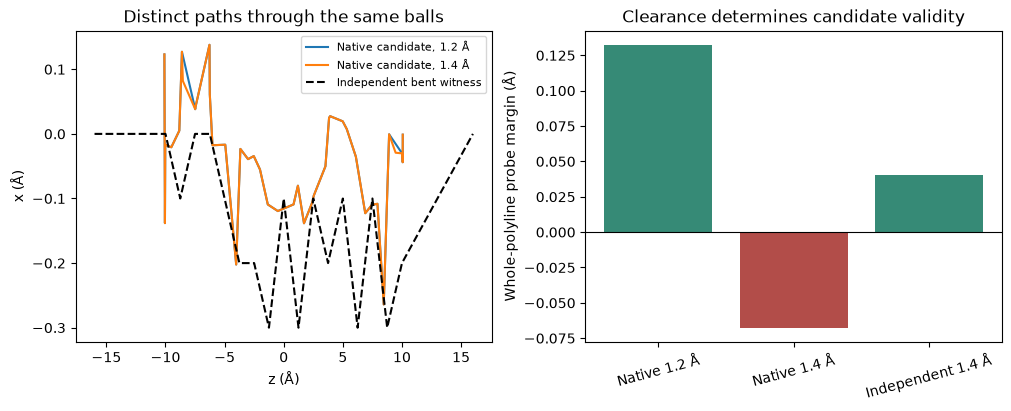

In [5]:
table(['Probe (Å)', 'Component', 'Candidate stations', 'All-atom minimum clearance (Å)', 'Probe margin (Å)', 'All segments clear?', 'Native collision validated?'], [
    [probe, row['component_id'], len(row['points']), f"{row['minimum_all_atom_clearance']:.9f}",
     f"{row['probe_margin']:.9f}", row['all_segments_clear'], row['native_is_collision_validated']]
    for probe, rows in candidates.items() for row in rows])

fig, axes = plt.subplots(1, 2, figsize=(10, 4), layout='constrained')
for probe, rows in candidates.items():
    for row in rows:
        points = np.asarray(row['points'])
        axes[0].plot(points[:, 2], points[:, 0], label=f'Native candidate, {probe} Å')
axes[0].plot(path[:, 2], path[:, 0], 'k--', label='Independent bent witness')
axes[0].set(xlabel='z (Å)', ylabel='x (Å)', title='Distinct paths through the same balls')
axes[0].legend(fontsize=8)
labels, margins = [], []
for probe, rows in candidates.items():
    for row in rows:
        labels.append(f'Native {probe} Å')
        margins.append(row['probe_margin'])
labels.append('Independent 1.4 Å')
margins.append(reference['path_minimum_clearance_angstroms'] - 1.4)
axes[1].bar(labels, margins, color=['#368a76' if value > 0 else '#b24d49' for value in margins])
axes[1].axhline(0, color='black', lw=.8)
axes[1].set(ylabel='Whole-polyline probe margin (Å)', title='Clearance determines candidate validity')
axes[1].tick_params(axis='x', labelrotation=15)
plt.show()

At the recorded source, both selected native candidates have minimum clearance
**1.332434868 Å**. The 1.2 Å candidate is clear on its supplied segments; the
1.4 Å candidate collides, with margin **−0.067565132 Å**. The separate bent
witness has positive margin **+0.040735021 Å** at 1.4 Å. This refutes neither
the existence of the passage nor the independently certified witness. It shows
why the shortest graph-center skeleton cannot yet be used as a physical
navigation trajectory. General certified paths remain owned by
[#76](https://github.com/uibcdf/topomt/issues/76).

## The large-probe result needs an all-atom interpretation

At 2.5 Å, the independent full-hull cover proves that the finite all-atom
probe-center set is empty. Initial DFND nevertheless has three wet components
and four public objects (`OpenConcavity`, `Mouth`, `Groove`, `Mouth`).
The local residence and gate operators use four and three obstacle atoms;
their success is not an all-atom certificate. We cannot yet attribute this
discrepancy to a particular solver error or alter the method to fit the answer.
[#181](https://github.com/uibcdf/topomt/issues/181) owns diagnosis and the
public qualification/promotion decision. This finding remains **needs_review**,
excluded from general failure or comparative paper claims.

The public audit retains all 445 mesh cells, source IDs, resident/connector
roles, dry banks, native supports and public relations. A nonempty registry or
a positive local solvent proxy must not be read as a proved free physical volume.

In [6]:
print('Independent large-probe exclusion:', reference['model_reference']['exclusion']['2.5'])
table(['Native component at 2.5 Å', 'Resident cells', 'Connector cells', 'Native links', 'Catalog family'], [
    [row['id'], row['n_resident_nodes'], row['n_transit_connector_nodes'], row['n_external_links'], row['family']]
    for row in topographies[2.5].dfnd.raw['wet_components']])
print('Captured attribution keys:', sorted(credits))
print('Saved original per-operation and per-Topography attribution is in native_observations.json.')

Independent large-probe exclusion: {'probe_angstroms': 2.5, 'coverage_margin_angstroms': 0.29642036776096603, 'strictly_covered': True}


Native component at 2.5 Å,Resident cells,Connector cells,Native links,Catalog family
1,24,4,1,pocket
2,6,1,1,pocket
3,0,1,1,surface_concavity


Captured attribution keys: ['context', 'items', 'name', 'schema', 'usage_tree', 'uses']
Saved original per-operation and per-Topography attribution is in native_observations.json.


## Disposition before another case or a comparison

Independent references are established for this exact tube: two free end
patches and an end-to-end route at 1.2/1.4 Å, and an empty finite probe-center
set at 2.5 Å. Native/public receiving remains **incomplete** under #180/#181;
general paths retain #76. The corresponding strict expected-failure tests are
pending scientific targets, not successful qualification.

Stay with this unit to address those owners. Original CAVER/MOLE or other
comparisons need a separately frozen protocol for atom radii, accessible-space
definition, start/end conditions and original execution; they have not been run
here. Existing four-atom applicability investigations #155/#156 remain separate.
No current result demonstrates superiority, biological accuracy or a global
optimum path. Volume precision is not measured in this stage.

The [case page](index.md) and [artifact guide](artifacts/cylinder_tube_v1/README.md)
provide the download, retained initial attempts, source history, attribution and
replay instructions. The [DFND book](../../../dfnd/index.md) explains the local
operators, physical boundaries, public meanings and path limitations.